#### Imports

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

In [2]:
df = pd.read_csv("Delivery_Data.csv")

df

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68
...,...,...,...,...,...,...,...,...,...
995,107,8.50,Clear,High,Evening,Car,13,3.0,54
996,271,16.28,Rainy,Low,Morning,Scooter,8,9.0,71
997,861,15.62,Snowy,High,Evening,Scooter,26,2.0,81
998,436,14.17,Clear,Low,Afternoon,Bike,8,0.0,55


#### Finding Missing Values


In [3]:
df.isna().sum()

Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs    30
Delivery_Time_min          0
dtype: int64

In [4]:
df.dtypes

Order_ID                    int64
Distance_km               float64
Weather                       str
Traffic_Level                 str
Time_of_Day                   str
Vehicle_Type                  str
Preparation_Time_min        int64
Courier_Experience_yrs    float64
Delivery_Time_min           int64
dtype: object

#### Filling Categorical Columns With NULL Values

In [5]:
col = ['Weather', 'Traffic_Level', 'Time_of_Day']

df[col] = df[col].fillna(df[col].mode().iloc[0])

df.isna().sum()

Order_ID                   0
Distance_km                0
Weather                    0
Traffic_Level              0
Time_of_Day                0
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs    30
Delivery_Time_min          0
dtype: int64

#### Filling Numerical Columns With NULL Values

In [6]:
df['Courier_Experience_yrs']  = df['Courier_Experience_yrs'].fillna(df['Courier_Experience_yrs'].mean())

df.isna().sum()

Order_ID                  0
Distance_km               0
Weather                   0
Traffic_Level             0
Time_of_Day               0
Vehicle_Type              0
Preparation_Time_min      0
Courier_Experience_yrs    0
Delivery_Time_min         0
dtype: int64

#### Outlier Analysis

In [7]:
df = df.drop(columns = 'Order_ID')

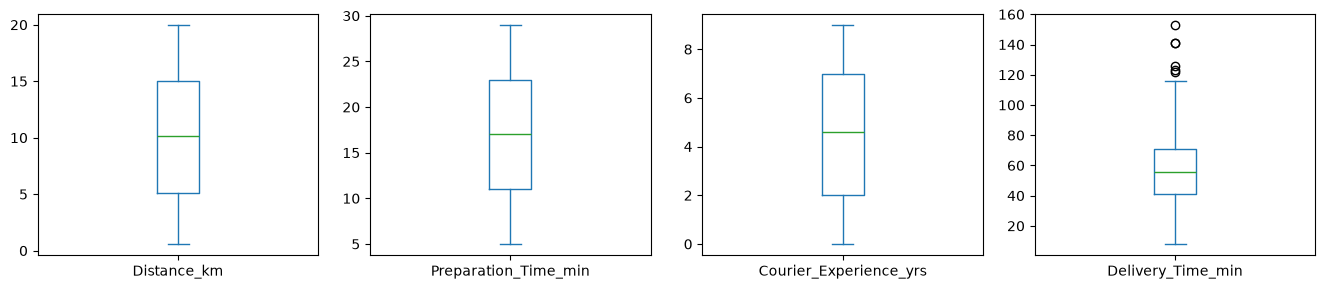

In [8]:
df.plot(kind="box",subplots=True,layout=(1,6),figsize=(20,3))
plt.tight_layout()

In [9]:
df['Delivery_Time_min'].describe()

count    1000.000000
mean       56.732000
std        22.070915
min         8.000000
25%        41.000000
50%        55.500000
75%        71.000000
max       153.000000
Name: Delivery_Time_min, dtype: float64

In [10]:
q1 = 41.0
q3 = 71.0

iqr = q3 - q1

minimum = q1 - (1.5 * iqr)
maximum = q3 + (1.5 * iqr)

print(f"Minimum IQR value : {minimum}")
print(f"Maximum IQR value : {maximum}")

Minimum IQR value : -4.0
Maximum IQR value : 116.0


In [11]:
df = df[
    (df['Delivery_Time_min'] > minimum)&
    (df['Delivery_Time_min'] < maximum)
]

<Axes: >

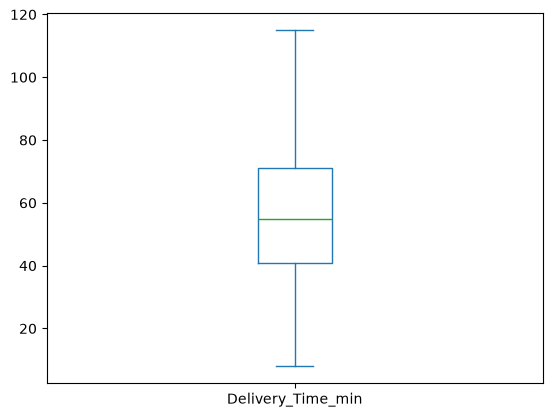

In [12]:
df['Delivery_Time_min'].plot(kind="box")

#### Splitting

In [13]:
x = df.iloc[:,:-1]
y = df.iloc[:,-1]

x
y

0      43
1      84
2      59
3      37
4      68
       ..
995    54
996    71
997    81
998    55
999    58
Name: Delivery_Time_min, Length: 992, dtype: int64

#### Finding Column Types for Encoding

In [14]:
col = ['Weather','Traffic_Level','Time_of_Day','Vehicle_Type']

x[col] = x[col].astype('category')

df.dtypes

Distance_km               float64
Weather                       str
Traffic_Level                 str
Time_of_Day                   str
Vehicle_Type                  str
Preparation_Time_min        int64
Courier_Experience_yrs    float64
Delivery_Time_min           int64
dtype: object

In [15]:
for col in col:
    print(x[col].unique())

['Windy', 'Clear', 'Foggy', 'Rainy', 'Snowy']
Categories (5, str): ['Clear', 'Foggy', 'Rainy', 'Snowy', 'Windy']
['Low', 'Medium', 'High']
Categories (3, str): ['High', 'Low', 'Medium']
['Afternoon', 'Evening', 'Night', 'Morning']
Categories (4, str): ['Afternoon', 'Evening', 'Morning', 'Night']
['Scooter', 'Bike', 'Car']
Categories (3, str): ['Bike', 'Car', 'Scooter']


In [16]:
ord_col = ['Traffic_Level']
nom_col = ['Weather','Time_of_Day','Vehicle_Type']

#### Label Encoding

In [17]:
le_traffic = LabelEncoder()

x['Traffic_Level'] = le_traffic.fit_transform(x['Traffic_Level'])

x

,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs
0,7.93,Windy,1,Afternoon,Scooter,12,1.0
1,16.42,Clear,2,Evening,Bike,20,2.0
2,9.52,Foggy,1,Night,Scooter,28,1.0
3,7.44,Rainy,2,Afternoon,Scooter,5,1.0
4,19.03,Clear,1,Morning,Bike,16,5.0
...,...,...,...,...,...,...,...
995,8.50,Clear,0,Evening,Car,13,3.0
996,16.28,Rainy,1,Morning,Scooter,8,9.0
997,15.62,Snowy,0,Evening,Scooter,26,2.0
998,14.17,Clear,1,Afternoon,Bike,8,0.0


#### One-Hot Encoding

In [18]:
x = pd.get_dummies(x, dtype=int, drop_first=True)

x

,Distance_km,Traffic_Level,Preparation_Time_min,Courier_Experience_yrs,Weather_Foggy,Weather_Rainy,Weather_Snowy,Weather_Windy,Time_of_Day_Evening,Time_of_Day_Morning,Time_of_Day_Night,Vehicle_Type_Car,Vehicle_Type_Scooter
0,7.93,1,12,1.0,0,0,0,1,0,0,0,0,1
1,16.42,2,20,2.0,0,0,0,0,1,0,0,0,0
2,9.52,1,28,1.0,1,0,0,0,0,0,1,0,1
3,7.44,2,5,1.0,0,1,0,0,0,0,0,0,1
4,19.03,1,16,5.0,0,0,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,8.50,0,13,3.0,0,0,0,0,1,0,0,1,0
996,16.28,1,8,9.0,0,1,0,0,0,1,0,0,1
997,15.62,0,26,2.0,0,0,1,0,1,0,0,0,1
998,14.17,1,8,0.0,0,0,0,0,0,0,0,0,0


#### Train-Test Split

In [19]:
x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.8, random_state=42)

#### Scaling

In [22]:
scaler = StandardScaler()

x_train = scaler.fit_transform(x_train)
x_test  = scaler.transform(x_test)

#### Model Building

In [23]:
model = LinearRegression()

model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](13,)","[16.62,-1.1 , 7.01,...,-0.09,-0.15,-0.4 ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,56.28
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(13)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](13,)","[35.02,32.59,31.42,...,23. ,20.9 ,17.81]"


#### Metrics

In [25]:
y_pred = model.predict(x_test)


In [30]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f'MAE:{mae:5.2f}   MSE:{mse:5.2f}    RMSE:{rmse:5.2f}   R2_SCORE:{r2:3f}')

MAE: 6.64   MSE:97.14    RMSE: 9.86   R2_SCORE:0.770390


In [32]:
joblib.dump(model, 'delay.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(le_traffic, 'le_traffic.pkl')

['le_traffic.pkl']